In [19]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from keras.layers import Dropout
from tensorflow.keras.layers import Dense, LSTM
from tensorflow.keras.metrics import RootMeanSquaredError, MeanAbsoluteError
from tensorflow.keras.models import Sequential
import matplotlib.pyplot as plt

In [11]:
# Step 1: Load the CSV file and split the data
dataframe = pd.read_csv('../preprocess/parking_time_series_with_features.csv', usecols=[1], engine='python')
data = dataframe.values

# Split data into training and test sets
train_size = int(len(data) * 0.8)
train, test = data[0:train_size], data[train_size:len(data)]

# Step 2: Prepare the data for LSTM
def create_dataset(data, time_step=1):
    x, y = [], []
    for i in range(len(data) - time_step - 1):
        a = data[i:(i + time_step), 0]
        x.append(a)
        y.append(data[i + time_step, 0])
    return np.array(x), np.array(y)

time_step = 10
x_train, y_train = create_dataset(train, time_step)
x_test, y_test = create_dataset(test, time_step)

# Reshape input to be [samples, time steps, features] which is required for LSTM
x_train = x_train.reshape(x_train.shape[0], x_train.shape[1], 1)
x_test = x_test.reshape(x_test.shape[0], x_test.shape[1], 1)

In [12]:
# Step 3: Define the model

def get_model(params, input_shape):
	model = Sequential()
	model.add(LSTM(units=params["lstm_units"], return_sequences=True, input_shape=(input_shape, 1)))
	model.add(Dropout(rate=params["dropout"]))

	model.add(LSTM(units=params["lstm_units"], return_sequences=True))
	model.add(Dropout(rate=params["dropout"]))

	model.add(LSTM(units=params["lstm_units"], return_sequences=True))
	model.add(Dropout(rate=params["dropout"]))

	model.add(LSTM(units=params["lstm_units"], return_sequences=False))
	model.add(Dropout(rate=params["dropout"]))

	model.add(Dense(1))

	model.compile(loss=params["loss"],
              	optimizer=params["optimizer"],
              	metrics=[RootMeanSquaredError(), MeanAbsoluteError()])

	return model

In [13]:
params = {
	"loss": "mean_squared_error",
	"optimizer": "adam",
	"dropout": 0.2,
	"lstm_units": 90,
	"epochs": 30,
	"batch_size": 128,
	"es_patience" : 10
}

model = get_model(params=params, input_shape=x_train.shape[1])

# Step 4: Train the model
es_callback = tf.keras.callbacks.EarlyStopping(monitor='val_root_mean_squared_error',
                                           	mode='min',
patience=params["es_patience"])

history = model.fit(
	x_train,
	y_train,
	validation_data=(x_test, y_test),
	epochs=params["epochs"],
	batch_size=params["batch_size"],
	verbose=1,
	callbacks=[es_callback]
)

Epoch 1/30


c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


864/864 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - loss: 210600.3750 - mean_absolute_error: 314.7711 - root_mean_squared_error: 458.8295 - val_loss: 92554.6094 - val_mean_absolute_error: 180.1427 - val_root_mean_squared_error: 304.2279
Epoch 2/30
864/864 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - loss: 169703.6250 - mean_absolute_error: 253.2177 - root_mean_squared_error: 411.8618 - val_loss: 71298.6406 - val_mean_absolute_error: 143.8495 - val_root_mean_squared_error: 267.0181
Epoch 3/30
864/864 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - loss: 136569.3594 - mean_absolute_error: 209.8140 - root_mean_squared_error: 369.5311 - val_loss: 53648.9844 - val_mean_absolute_error: 120.5896 - val_root_mean_squared_error: 231.6225
Epoch 4/30
864/864 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - loss: 112440.7656 - mean_absolute_error: 186.6565 - root_mean_squared_error: 335.2777 - val_loss: 39188.5078 - val_mean_absolute_error: 100.1609 - val_root_mean_squared_error: 197.9609
Epoch 5/30
864/864 ━━━━━━━━━━━━━━━━━━━━ 16s 19m

3456/3456 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step
864/864 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


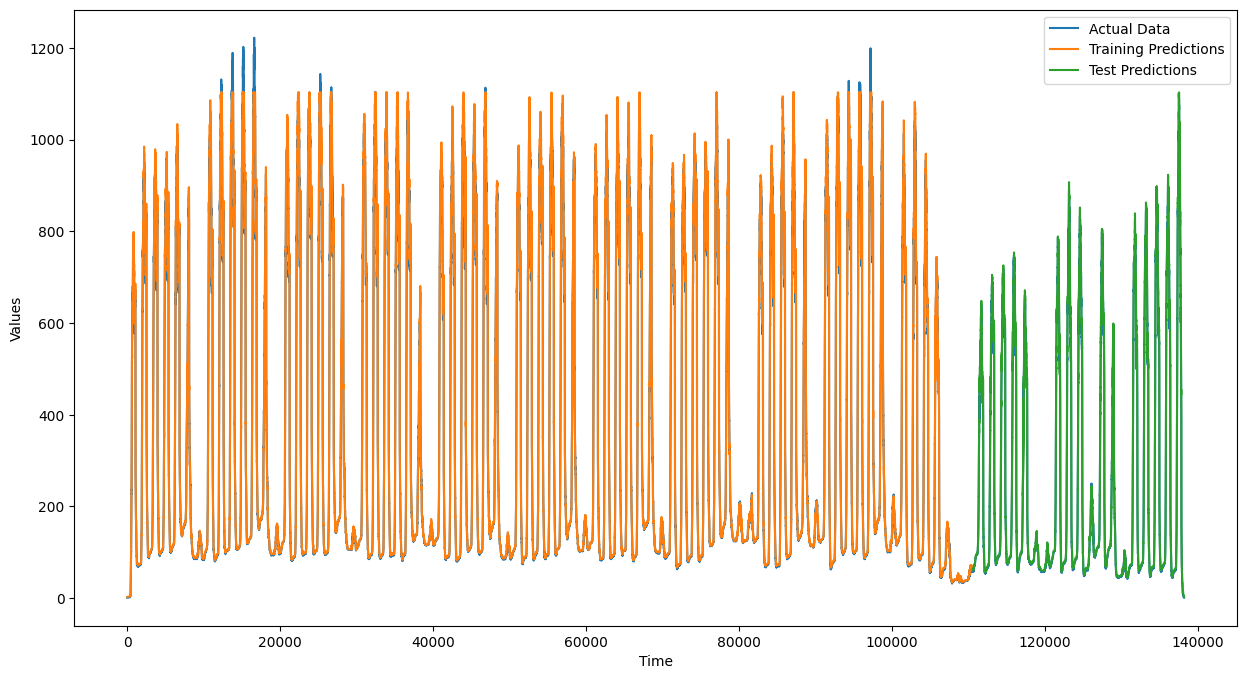

Mean Squared Error: 136.7062013670878


In [25]:
# Step 5: Predict values
train_predict = model.predict(x_train)
test_predict = model.predict(x_test)

# Prepare data for plotting
train_predict_plot = np.empty((len(data), 1))
train_predict_plot[:, :] = np.nan
train_predict_plot[time_step:len(train_predict)+time_step, 0] = train_predict.flatten()

test_predict_plot = np.empty((len(data), 1))
test_predict_plot[:, :] = np.nan
test_predict_plot[len(train_predict)+(time_step*2)+1:len(data)-1, 0] = test_predict.flatten()

# Plot actual data, training predictions, and test predictions
plt.figure(figsize=(15, 8))
plt.plot(data, label='Actual Data')
plt.plot(train_predict_plot, label='Training Predictions')
plt.plot(test_predict_plot, label='Test Predictions')
plt.xlabel('Time')
plt.ylabel('Values')
plt.legend()
plt.show()

# Step 6: Print MSE
mse = mean_squared_error(y_test, test_predict)
print(f"Mean Squared Error: {mse}")
